# 02 — Transcripts, turns and candidate pairs

**Stage question.** What is one unit of analysis in this corpus — one partner turn followed by one reply — and how many of them does the selected sample contain before any audio is examined?

| | |
|---|---|
| **Purpose** | Fetch the word-timed transcripts and voice-activity segments for the selected sessions, build turns by the preregistered rule, and form the candidate partner → reply pairs. |
| **Input** | `manifests/coda_download_manifest.csv` (notebook 01). About 20 kB per participant file, fetched to `data/raw/transcript/` and `data/raw/vad/`. |
| **Processing** | Fetch (threaded, skipping files already present) → check that transcripts and voice activity agree → words → inter-pausal units → turns → embedded backchannels set aside → candidate pairs within each interaction → availability of a distant same-speaker donor (N2). |
| **Output** | `data/processed/turns.parquet`, `data/processed/pairs_candidates.parquet`, `data/processed/transcript_stats.parquet` (Drive; git-ignored). `results/turns/`: funnel, transcript agreement summary, run record. `results/acquisition/text_fetch_log_<stage>.csv` with checksums. `figures/02_turns/`. |
| **Scientific assumptions** | Word timestamps (from the WhisperX aligner) place words to within tens of milliseconds; the two participants' files of one interaction share a time origin (checked in notebook 03); the turn rule is fixed before any prosody is seen. |
| **Failure modes** | A transcript misaligned to its audio (flagged by low agreement with voice activity); missing transcripts (the interaction cannot yield pairs and is counted); a turn rule that fragments speech into artificial pairs (checked by the embedded-unit share and the turn-duration distribution). |
| **What to look at** | The funnel table, the turn-duration distribution, the reply-onset distribution, and the share of pairs that have an N2 donor. |

**Terms used in this notebook.**

- **Transcript with word timing** — every word with its start and end time in seconds. Produced upstream by WhisperX, an automatic speech recogniser with forced alignment.
- **VAD (voice activity detection)** — where a speaker is talking, as start–end segments. Produced upstream by Silero VAD from the speaker's own microphone.
- **Inter-pausal unit (IPU)** — a stretch of one speaker's words not interrupted by a silence of 50 ms or more.
- **Turn** — a maximal run of one speaker's IPUs with no speech from the partner *between* them.
- **Embedded unit** — a partner IPU lying entirely inside the other person's turn, typically an overlapped "yeah" or "mm-hm". The speaker did not give up the floor, so it neither ends the turn nor forms a pair. It is kept and counted.
- **Pair** — a partner turn followed by the reply turn: two consecutive turns by different speakers in the same interaction. This is the unit the study predicts from.
- **Reply onset gap** — reply start minus partner end. Negative means the reply began while the partner was still speaking.
- **N2 donor** — for the within-dyad control, a turn by the same partner speaker at least 10 turns away in the same interaction (preregistration §6).

In [1]:
# Runtime setup — identical in every notebook.
# Colab: mounts Google Drive and uses MyDrive/coda (a copy of the repository) as
#        the project root, then installs the pinned measurement stack.
# Local: uses the repository checkout.
# Every path used below is relative to that root, so Drive and the repository
# have exactly the same layout and outputs can be copied back unchanged.
import os, sys, subprocess
from pathlib import Path

try:
    from google.colab import drive  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    ROOT = Path(os.environ.get('CODA_ROOT', '/content/drive/MyDrive/coda'))
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r',
                    str(ROOT / 'requirements-colab.txt')], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

os.environ['CODA_ROOT'] = str(ROOT)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.runtime import runtime_report
REPORT = runtime_report()

Mounted at /content/drive
runtime        colab   python 3.13.16   cpus 2
memory         12.3 GB free of 13.6 GB
gpu            none (not needed for this stage unless stated)
project disk   13.3 GB free   root = /content/drive/MyDrive/coda
scratch disk   93.4 GB free   (audio lives here briefly)
code           fingerprint 51ce4acb032a1d84
artifacts      manifest=True, metadata=True, transcripts=False, turns=False, audio_pass_sessions=0, channel_qc=False


**Runtime check.** The cell above prints free disk on the project root (Drive on Colab) and on the scratch disk where audio briefly lives, memory, CPU count, GPU, the code fingerprint, and which pipeline artifacts already exist. The code fingerprint identifies the exact source and configuration that ran; it is written into every run record and is how a result produced on Drive is matched back to the repository.

In [2]:
# Parameters
STAGE = 'pilot'               # 'pilot' (40 sessions) or 'sample' (pilot + 210)
RUN_FROM_SCRATCH = False      # True: rebuild turn tables even if present
FETCH_WORKERS = 16            # parallel requests; text files are tiny

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DataConfig
from src.paths import paths
from src.data import seamless as S
from src.data.acquire import fetch_text_files, build_turn_tables, transcript_vad_agreement
from src.runtime import write_run_record
from src.viz import style

P = paths().ensure()
style.apply()
OUT = P.results / 'turns'
OUT.mkdir(parents=True, exist_ok=True)
# Figures are filed per stage so a later run cannot overwrite an earlier one.
FIGDIR = f'02_turns__{STAGE}'
ACQ = P.results / 'acquisition'
ACQ.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(P.manifest, dtype=str)
manifest['selection_rank'] = manifest['selection_rank'].astype(int)
rows = S.select_stage(manifest, STAGE)
print(f"stage {STAGE}: {rows['session_key'].nunique()} sessions, "
      f"{rows['interaction_key'].nunique()} interactions, {len(rows)} participant files")

stage pilot: 40 sessions, 458 interactions, 916 participant files


## 1. Fetch transcripts and voice-activity segments

Files already on Drive are not fetched again; their checksum is still recorded, so the log describes every file the stage used.

In [4]:
log = fetch_text_files(rows, P, workers=FETCH_WORKERS)
log['path'] = log['path'].map(lambda p: Path(p).resolve().relative_to(P.root.resolve()).as_posix())
log.to_csv(ACQ / f'text_fetch_log_{STAGE}.csv', index=False)
pd.crosstab(log['kind'], log['status'])

status,fetched
kind,
transcript,916
vad,916


**Reading the table.** `fetched` were downloaded now, `exists` were already present, `missing` are absent upstream. The dataset marks transcripts as optional, so a missing transcript is possible; its interaction cannot yield pairs and appears in the funnel below rather than disappearing.

## 2. Do transcripts and voice activity agree?

Words come from one system and voice activity from another, run on the same microphone. If a transcript is aligned to the wrong audio or shifted in time, its words will fall outside the speaker's own speech. The measure below is the share of word time inside the speaker's own VAD segments, per participant file.

,count,mean,std,min,5%,50%,max
vendor_id,,,,,,,
00,84.0,0.867,0.138,0.275,0.545,0.919,1.000
01,94.0,0.792,0.261,0.000,0.172,0.902,0.998
02,287.0,0.850,0.188,0.000,0.427,0.924,0.999
03,438.0,0.730,0.236,0.000,0.152,0.810,0.998


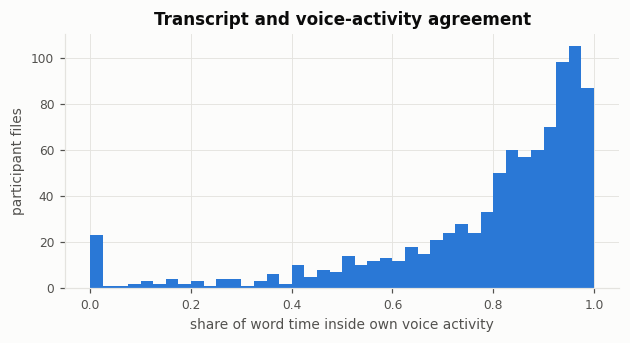

In [5]:
agree = transcript_vad_agreement(rows, P)
agree.to_parquet(P.processed / 'transcript_vad_agreement.parquet', index=False)
desc = agree.groupby('vendor_id')['words_inside_vad'].describe(percentiles=[.05, .5]).round(3)
desc.to_csv(OUT / f'transcript_vad_agreement_{STAGE}.csv')
display(desc)

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.hist(agree['words_inside_vad'].dropna(), bins=np.linspace(0, 1, 41), color=style.SERIES[0])
ax.set_xlabel('share of word time inside own voice activity')
ax.set_ylabel('participant files')
ax.set_title('Transcript and voice-activity agreement')
style.save(fig, P.figures, FIGDIR, 'transcript_vad_agreement')
plt.show()

**What is plotted.** For each participant file, the fraction of the time covered by transcribed words that also lies inside that speaker's detected speech.

**Why it matters.** Turn boundaries come from word times. If those are wrong, every turn-level measurement is taken over the wrong stretch of audio, and nothing downstream would announce it.

**What would indicate a problem.** A separate cluster of files near zero (words placed where the speaker is silent) rather than a single mass near one. A long left tail is expected from very short files and from brief words the VAD misses.

**Conclusion.** Record the median and the 5th percentile per site from the table. No file is excluded on this measure: a cut chosen after looking would be a tuning path into the sample. Files in the lower tail are listed in `data/processed/transcript_vad_agreement.parquet` and can be inspected by ear if the audit in notebook 04 points to them.

## 3. Turns and candidate pairs

The rule (preregistration) is applied per interaction. It is fixed now, before any prosody has been measured, so it cannot be adjusted towards a result.

In [6]:
turns_path = P.processed / 'turns.parquet'
pairs_path = P.processed / 'pairs_candidates.parquet'
stats_path = P.processed / 'transcript_stats.parquet'
stage_path = P.processed / 'turns_stage.json'
built_for = json.loads(stage_path.read_text())['stage'] if stage_path.exists() else None

if turns_path.exists() and built_for == STAGE and not RUN_FROM_SCRATCH:
    turns, pairs, stats = (pd.read_parquet(p) for p in (turns_path, pairs_path, stats_path))
    print('loaded existing turn tables for stage', STAGE)
else:
    turns, pairs, stats = build_turn_tables(rows, P, DataConfig().n2_min_turn_distance)
    turns.to_parquet(turns_path, index=False)
    pairs.to_parquet(pairs_path, index=False)
    stats.to_parquet(stats_path, index=False)
    stage_path.write_text(json.dumps({'stage': STAGE}))
    print('built turn tables for stage', STAGE)

main = turns[~turns['embedded']]
print(f"turn units {len(turns):,}  (embedded {turns['embedded'].sum():,}, "
      f"{turns['embedded'].mean():.1%})")
print(f"turns {len(main):,}   candidate pairs {len(pairs):,}")

/content/drive/MyDrive/coda/src/data/turns.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  allu = pd.concat(units, ignore_index=True)


built turn tables for stage pilot
turn units 29,675  (embedded 9,995, 33.7%)
turns 19,680   candidate pairs 19,228


### A worked example

The first turns of one interaction, so the rule can be checked against the words it was applied to. Embedded units are shown under the turn that hosts them.

In [7]:
ik = rows.sort_values('selection_rank')['interaction_key'].iloc[0]
ex = turns[turns['interaction_key'] == ik].copy()
ex['order'] = ex['start']
ex['text'] = ex['text'].str.slice(0, 90)
ex.sort_values('order')[['turn_id', 'speaker', 'embedded', 'start', 'end', 'n_words', 'text']].head(14)

,turn_id,speaker,embedded,start,end,n_words,text
6583,V02_S3081_I00000125_T0000,V02_P4062,False,0.000,10.006,20,Can you think of a childhood memory that you h...
6584,V02_S3081_I00000125_T0001,V02_P4059,False,12.969,66.038,150,"Overjoyed or proud? Yeah, like one time when I..."
6585,V02_S3081_I00000125_T0002,V02_P4062,False,67.017,120.247,149,For me as a kid I was just really dope that I ...
6586,V02_S3081_I00000125_T0003,V02_P4059,False,120.628,139.659,51,That is like being able to like be like see a ...
6587,V02_S3081_I00000125_T0004,V02_P4062,False,140.205,140.545,1,That's
6588,V02_S3081_I00000125_T0005,V02_P4059,False,140.360,177.631,110,She got me into it. So I was getting some pret...
6590,V02_S3081_I00000125_E0000,V02_P4062,True,140.645,140.725,1,fine.
6589,V02_S3081_I00000125_T0006,V02_P4062,False,179.637,200.744,65,"I would say, yeah, that was just pretty much m..."


**Reading the example.** Each `_T` row is a turn; the speaker alternates by construction. `_E` rows are embedded units: a short partner utterance lying entirely inside the other speaker's turn. They sit inside their host turn's time span and are not treated as replies.

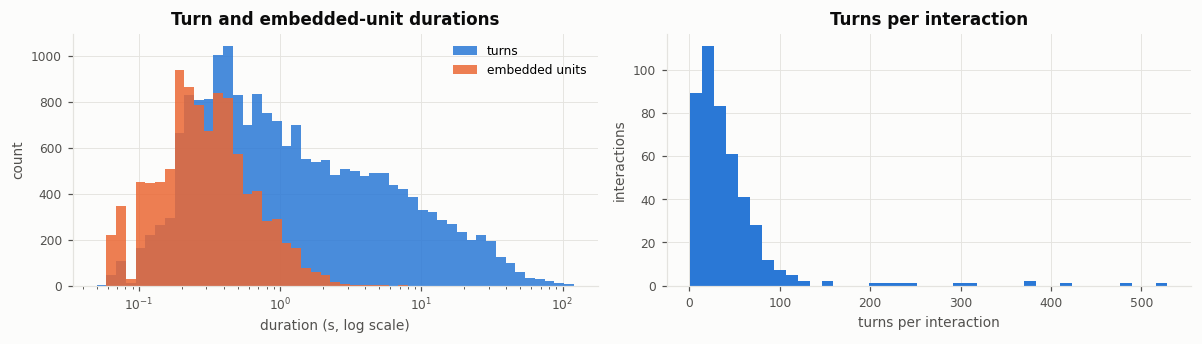

,turn duration (s),turns per interaction
count,19680.00,452.00
mean,4.40,43.54
std,9.67,55.39
min,0.02,1.00
10%,0.22,8.00
25%,0.38,17.00
50%,0.96,31.00
75%,3.92,53.00
90%,11.88,74.90
max,250.74,529.00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
bins = np.logspace(np.log10(0.05), np.log10(120), 50)
ax.hist(main['duration'], bins=bins, color=style.SERIES[0], alpha=0.85, label='turns')
ax.hist(turns.loc[turns['embedded'], 'duration'], bins=bins, color=style.SERIES[1], alpha=0.85,
        label='embedded units')
ax.set_xscale('log')
ax.set_xlabel('duration (s, log scale)')
ax.set_ylabel('count')
ax.set_title('Turn and embedded-unit durations')
ax.legend()
ax = axes[1]
per_int = main.groupby('interaction_key').size()
ax.hist(per_int, bins=40, color=style.SERIES[0])
ax.set_xlabel('turns per interaction')
ax.set_ylabel('interactions')
ax.set_title('Turns per interaction')
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'turn_structure')
plt.show()
display(pd.DataFrame({'turn duration (s)': main['duration'].describe(percentiles=[.1, .25, .5, .75, .9]),
                      'turns per interaction': per_int.describe(percentiles=[.1, .25, .5, .75, .9])}).round(2))

**What is plotted.** Left: durations of turns and of embedded units, on a log scale. Right: the number of turns in each interaction.

**Why it matters.** Turns are what the eight delivery measures are computed over. Very short turns carry little pitch information; very long turns are extended stories. The embedded units should be short — if they were long, the rule would be discarding real turns.

**What would indicate a problem.** Embedded units with durations comparable to turns; a spike of interactions with one or two turns (a speaker transcribed as silent); turns per interaction far below the pilot yield estimate made from the dataset's extra files (median about 28, measured before selection).

**Conclusion.** Record the median turn duration and turns per interaction. How many short turns survive prosody measurement is decided in notebook 04 by the voiced-frame requirement, not here.

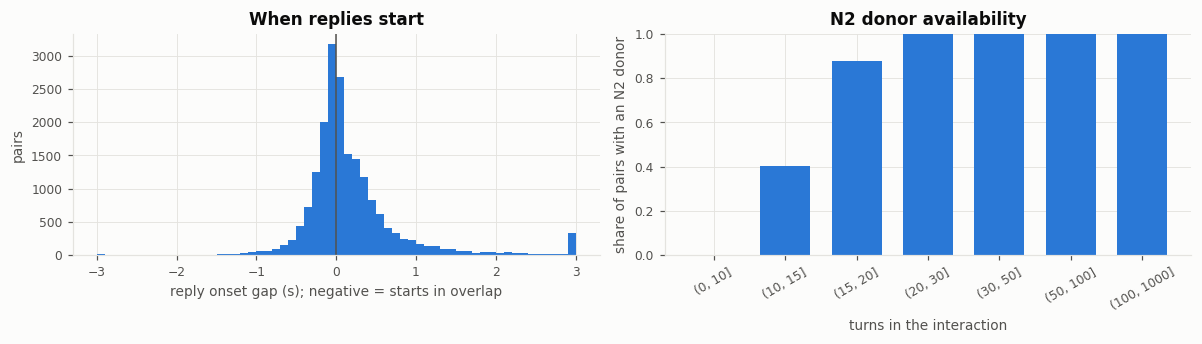

pairs starting in overlap: 43.3%
pairs with an N2 donor in the same interaction: 96.6%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ax = axes[0]
g = pairs['gap_s'].clip(-3, 3)
ax.hist(g, bins=np.linspace(-3, 3, 61), color=style.SERIES[0])
ax.axvline(0, color=style.INK_SECONDARY, linewidth=1)
ax.set_xlabel('reply onset gap (s); negative = starts in overlap')
ax.set_ylabel('pairs')
ax.set_title('When replies start')
ax = axes[1]
b = pd.cut(pairs['turns_in_interaction'], [0, 10, 15, 20, 30, 50, 100, 1000])
share = pairs.groupby(b, observed=True)['n2_candidates'].apply(lambda s: (s > 0).mean())
ax.bar(share.index.astype(str), share.values, color=style.SERIES[0], width=0.7)
ax.set_ylim(0, 1)
ax.set_xlabel('turns in the interaction')
ax.set_ylabel('share of pairs with an N2 donor')
ax.set_title('N2 donor availability')
ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
style.save(fig, P.figures, FIGDIR, 'reply_onset_and_n2')
plt.show()
print(f"pairs starting in overlap: {(pairs['gap_s'] < 0).mean():.1%}")
print(f"pairs with an N2 donor in the same interaction: {(pairs['n2_candidates'] > 0).mean():.1%}")

**What is plotted.** Left: reply onset relative to the end of the partner turn, clipped at ±3 s. Right: the share of pairs for which a same-speaker turn at least 10 turns away exists in the same interaction, grouped by the interaction's length in turns.

**Why it matters.** The left panel shows how much replies overlap their partner turns. An overlapping reply's audio is recorded while the partner is still talking, which is where echo suppression may alter the reply's own level; notebook 04 measures that. The right panel shows whether the within-dyad control (N2) can be formed. Pairs without a donor cannot enter the N2 comparison, and that loss must not depend on the condition being tested (preregistration §8).

**What would indicate a problem.** A large mass of replies starting well before the partner ends (more than a second) would suggest mis-timed words rather than overlap. Low N2 availability overall would force the within-interaction control to rest on long interactions only.

**Conclusion.** Short interactions cannot supply an N2 donor, by definition: fewer than about 11 turns leave no same-speaker turn 10 away. Record the overall share. On the dataset's extra files, measured before selection, it was about 95%.

## 4. The funnel, stage 1: before audio

The first half of the sample-attrition record, from the selected sessions to candidate pairs. Notebook 04 continues it through channel quality control and prosody.

In [10]:
ints_all = rows['interaction_key'].nunique()
ints_text = stats.groupby('interaction_key')['transcript'].apply(lambda s: (s == 'present').all()).sum()
funnel = pd.DataFrame([
    ('selected sessions', rows['session_key'].nunique()),
    ('selected interactions', ints_all),
    ('interactions with both transcripts', int(ints_text)),
    ('turn units (turns + embedded)', len(turns)),
    ('turns (embedded set aside)', len(main)),
    ('candidate pairs', len(pairs)),
    ('candidate pairs with an N2 donor', int((pairs['n2_candidates'] > 0).sum())),
], columns=['step', 'count'])
funnel.to_csv(OUT / f'funnel_stage1_{STAGE}.csv', index=False)
funnel

,step,count
0,selected sessions,40
1,selected interactions,458
2,interactions with both transcripts,458
3,turn units (turns + embedded),29675
4,turns (embedded set aside),19680
5,candidate pairs,19228
6,candidate pairs with an N2 donor,18581


In [11]:
per_session = pairs.groupby('session_key').size()
print(f"candidate pairs per session: median {per_session.median():.0f}, "
      f"range {per_session.min()}–{per_session.max()}")
rec = write_run_record(OUT / f'02_run_record_{STAGE}.json', '02_transcripts_and_turns', {
    'stage': STAGE, 'ipu_gap_s': 0.05, 'n2_min_turn_distance': DataConfig().n2_min_turn_distance,
    'funnel': dict(zip(funnel['step'], funnel['count'].astype(int))),
    'untimed_words': int(stats['n_words_untimed'].sum()),
    'timed_words': int(stats['n_words_timed'].sum()),
})
print('run record written')

candidate pairs per session: median 388, range 82–2568
run record written


## Summary

- Turns and pairs are built by a rule fixed before any prosody was measured, and the rule's behaviour on a concrete interaction is shown above.
- Every step from selected sessions to candidate pairs is counted.
- The within-interaction N2 control is feasible for the share of pairs reported above; the rest cannot enter the N2 comparison and are counted rather than dropped silently.

**What this stage does not establish.** That the audio of these turns can be measured. Channel quality and pitch tracking are notebooks 03 and 04.

**Next.** `03_audio_pass` on a **CPU** Colab runtime: stream each interaction's audio, measure it, delete it.